## Descriptive data

Total changes of mid price
3784
Spread proportion
spread
1.0     9.919317e-01
2.0     7.880886e-03
3.0     1.805272e-04
4.0     1.235530e-08
5.0     5.448521e-06
6.0     1.463985e-06
16.0    4.262039e-09
Name: dt, dtype: float64
Rows with no mid price: 13


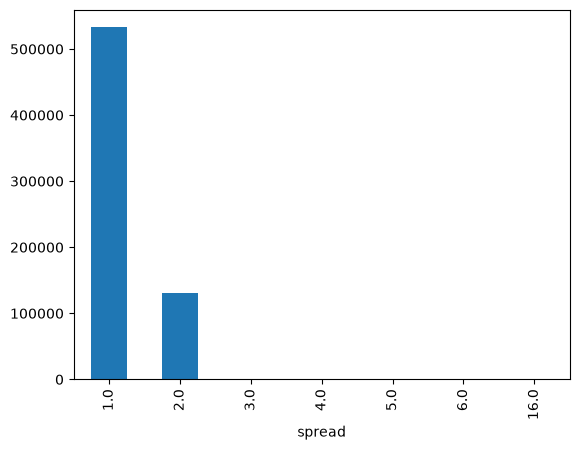

In [2]:
import pandas as pd 
df = pd.read_csv("../Data/indicators_msft.csv")
print("Total changes of mid price")
print(df["mid_changed"].sum())
s = df["spread"].dropna()
print("Spread proportion")
s.value_counts().sort_index().plot(kind="bar")
d = df.dropna(subset=["spread"]).copy()
d["dt"] = d["timestamp"].shift(-1) - d["timestamp"]   # how long each state lasted
print(d.groupby("spread")["dt"].sum() / d["dt"].sum())
print(f'Rows with no mid price: {df["spread"].isna().sum()}')

                  mean  count
prev_I1                      
(-1.0, -0.8]  0.021469    885
(-0.8, -0.6]  0.270677    133
(-0.6, -0.4]  0.170306    229
(-0.4, -0.2]  0.195783    332
(-0.2, 0.0]   0.304054    296
(0.0, 0.2]    0.574144    263
(0.2, 0.4]    0.713137    373
(0.4, 0.6]    0.755102    245
(0.6, 0.8]    0.846154    130
(0.8, 1.0]    0.987751    898


<Axes: xlabel='I1 just before the move', ylabel='P(up move)'>

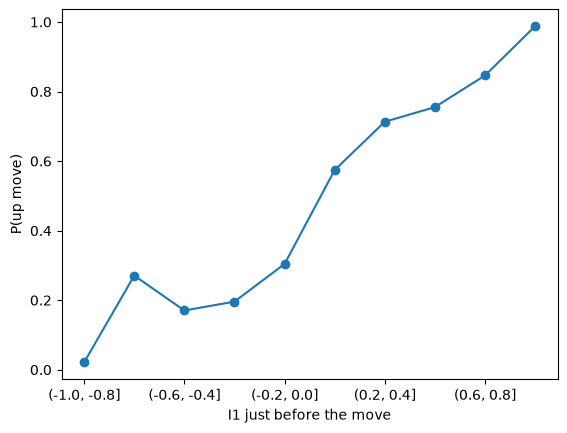

In [5]:
import numpy as np

d = df.dropna(subset=["double_mid"]).copy()
d["prev_I1"] = d["imbalance_1"].shift(1)
d["prev_Ik"] = d["imbalance_k"].shift(1)
d["move"] = d["double_mid"].diff()

ch = d[d["mid_changed"] == 1].copy()
ch["up"] = ch["move"] > 0

bins = np.linspace(-1, 1, 11)                     # 10 buckets of width 0.2
res = ch.groupby(pd.cut(ch["prev_I1"], bins), observed=True)["up"].agg(["mean", "count"])
print(res)
res["mean"].plot(marker="o", ylabel="P(up move)", xlabel="I1 just before the move")
